# Chaotic Kolmogorov flow, Re = 500: comparing optimizers

This notebook is one of three problems on which we compare **Adam**, **Muon** and **SOAP** (and, on Burgers and Darcy, **Muon-spec**) as optimizers for the **physics-informed neural operator (PINO)** (Li, Zheng et al., *Physics-Informed Neural Operator for Learning Partial Differential Equations*, arXiv:2111.03794).

The protocol follows the paper's Table 1:
- **Phase 1, operator learning.** Train a Fourier neural operator (FNO) with a data loss on a *coarse* grid plus a PDE-residual loss on a *finer* grid, then measure test error on several grids.
- **Phase 2, instance-wise fine-tuning.** Start from the Adam-trained operator and minimize the PDE loss on one test instance at a time (no data), tracking the error against a reference solution.

For each problem, all optimizers share the same initialization, data, batches and cosine learning-rate schedule. Learning rates are chosen on a validation set (never the test set).
- **Muon:** orthogonalizes updates of the hidden weight matrices; Adam handles the rest.
- **SOAP:** runs Adam in Shampoo's eigenbasis for every tensor.
- **Muon-spec** (`muon_spectral`): Muon that also orthogonalizes each Fourier mode's complex weight matrix, so it covers the spectral weights (99.6% of the parameters) that plain Muon leaves to Adam.

Both are implemented in `pino_bench.py`.

**Scale.** These are CPU runs (2 cores) with a half-width FNO (32 channels; the paper uses 64) and fewer iterations than the paper. Absolute errors are therefore above the paper's; the point is the **like-for-like comparison** of the optimizers.

This notebook only *reads* the saved results in `../results/kolmogorov` (set `RUN_EXPERIMENT = True` to regenerate them).

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))          # repo root: pino_bench.py, experiments.py, analysis.py
import pandas as pd, matplotlib.pyplot as plt
import analysis as an, experiments as ex
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 60)
PDE = "kolmogorov"


## Problem

2D Navier–Stokes in vorticity form on the torus $[0, 2\pi]^2$: $w_t + u\cdot\nabla w = \tfrac{1}{Re}\Delta w + f$ with $Re = 500$, $f = -4\cos(4y)$ and $T = 0.125$.

- **Initial states:** taken on the chaotic attractor, by spinning up random fields for 8 time units and then sampling snapshots 0.4 apart.
- **Reference solutions:** pseudo-spectral on **256²** with IF-RK4, stored at 128² × 33. Validation and test samples come from trajectories not used for training.
- **Training data:** 200 trajectories at **32² × 17**, plus a pool of 400 initial conditions for the PDE loss on **128² × 33**.
- **Grid choice:** notebook 04 shows the 128² PDE loss is a faithful target on attractor states (its minimizer lies 0.9% from the reference), while 64² is not (≈8%).
- **Time derivative:** central differences on the interior frames, as in the paper. This gives $N-1$ equations for $N$ unknown frames, so the loss has a family of exact minimizers. The fine-tuning is re-run below with the square, well-posed **Crank–Nicolson** residual (`cfg["time_scheme"] = "cn"`).
- **Loss weights:** data 5, residual 1, initial condition 5.
- **Test grids:** 32² × 17, 64² × 33 and 128² × 33 (40 test instances).
- **Model and training:** FNO with width 32 and 8 × 8 × 8 modes, 3000 iterations, batch 2 + 1, **1 seed**.
- **No learning-rate sweep (too expensive on CPU):** Adam and Muon at 1e-3, SOAP at 3e-3.

### Configuration
This is the exact configuration used for the saved results (`experiments.cfg_for`).

In [2]:
cfg = ex.cfg_for(PDE)
{k: cfg[k] for k in cfg if k not in ("gen",)}

{'Re': 500.0,
 'T': 0.125,
 'n_data': 200,
 'n_pde': 400,
 'n_val': 10,
 'n_test': 40,
 'model': {'modes': (8, 8, 8),
  'width': 32,
  'layers': 4,
  'pad_frac': 0.25,
  'pad_mode': 'points'},
 'train': {'iters': 3000,
  'bs_data': 2,
  'bs_pde': 1,
  'data_res': (32, 17),
  'pde_res': (128, 33),
  'weights': {'data': 5.0, 'f': 1.0, 'ic': 5.0}},
 'test_res': [(32, 17), (64, 33), (128, 33)],
 'val_res': (128, 33),
 'finetune': {'iters': 400,
  'n_instances': 2,
  'anchor': 0.0,
  'n_sweep_instances': 2,
  'sweep_frac': 0.5},
 'seeds': [0],
 'sweep': None}

### Reproducing

In [3]:
# Re-running the experiment from scratch takes about 20 hours on 2 CPU cores (resumable; see experiments.py).
# Results are written to ../runs/results; point the analysis cells at it with RESULTS = "../runs/results".
RUN_EXPERIMENT = False
RESULTS = an.RESULTS          # the saved results shipped with the repo
if RUN_EXPERIMENT:
    ex.run(PDE)
    RESULTS = os.path.join(ex.ROOT, "results")

## Phase 1: operator learning
Final test error (%), mean ± std over seeds, for each test grid.

In [4]:
an.results_table(PDE, RESULTS)

,lr,seeds,"test (32, 17)","test (64, 33)","test (128, 33)",time / run (min)
optimizer,,,,,,
Adam,0.001,1,34.98,34.69,34.70,272.0
Muon,0.001,1,34.58,34.27,34.27,391.5
SOAP,0.003,1,24.82,33.34,35.19,507.8


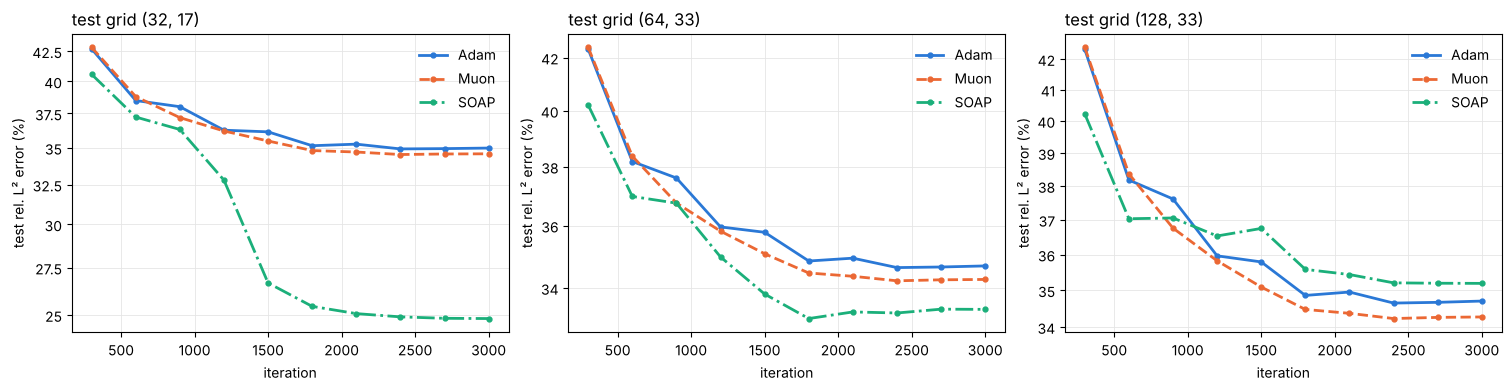

In [5]:
fig = an.plot_phase1(PDE, RESULTS, x='it'); plt.show()

The same curves against wall time:

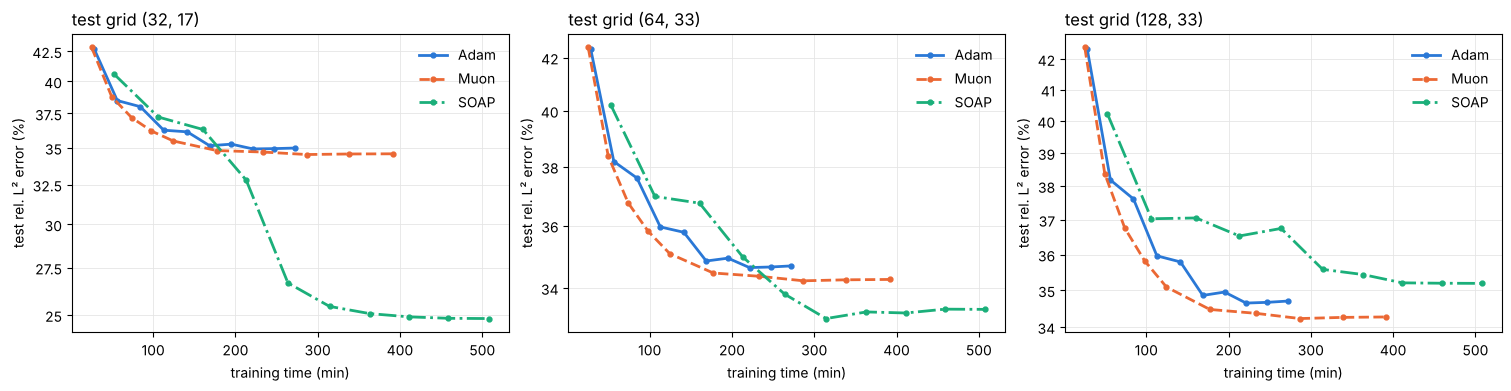

In [6]:
fig = an.plot_phase1(PDE, RESULTS, x='time'); plt.show()

## Phase 2: instance-wise fine-tuning
Each optimizer fine-tunes the **same** Adam-trained operator (seed 0) on each test instance, minimizing only the PDE loss, without the anchor term. The error is measured against the reference solution on the PDE grid.

In [7]:
an.ft_table(PDE, RESULTS)

,lr,instances,steps,start (%),final (%),final per instance (%),time / instance (s)
optimizer,,,,,,,
Adam,0.001,2,400,31.465,20.215,"[20.601, 19.829]",2372
Muon,0.001,2,400,31.465,20.107,"[20.398, 19.815]",2343
SOAP,0.003,2,400,31.465,10.155,"[10.844, 9.466]",2636


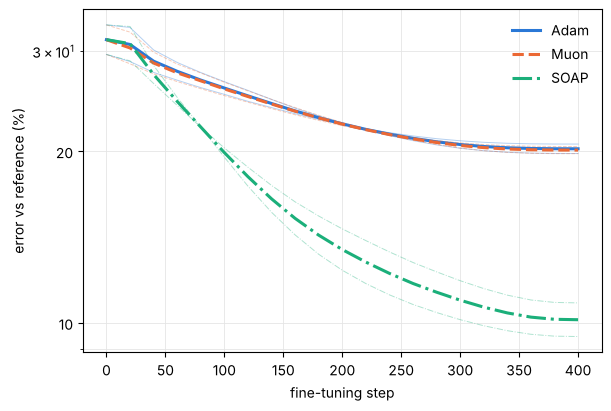

In [8]:
fig = an.plot_phase2(PDE, RESULTS, x='it'); plt.show()

### Fine-tuning rerun with the Crank–Nicolson time residual
Same operator, instances, steps and learning rates; only the time residual changes. `floors.json` holds the error of the exact minimizer of the CN loss on each instance (L-BFGS directly on the grid values).

In [9]:
import json
CN = os.path.join(an.RESULTS, "cn_finetune")
print("floor (%):", {k: round(100 * v, 2) for k, v in json.load(open(os.path.join(CN, "floors.json"))).items()})
an.ft_table(PDE, CN)

floor (%): {'410': 0.7, '411': 0.7}


,lr,instances,steps,start (%),final (%),final per instance (%),time / instance (s)
optimizer,,,,,,,
Adam,0.001,2,400,31.465,20.183,"[20.597, 19.769]",1952
Muon,0.001,2,400,31.465,20.063,"[20.392, 19.733]",1952
SOAP,0.003,2,400,31.465,10.123,"[10.869, 9.377]",2072


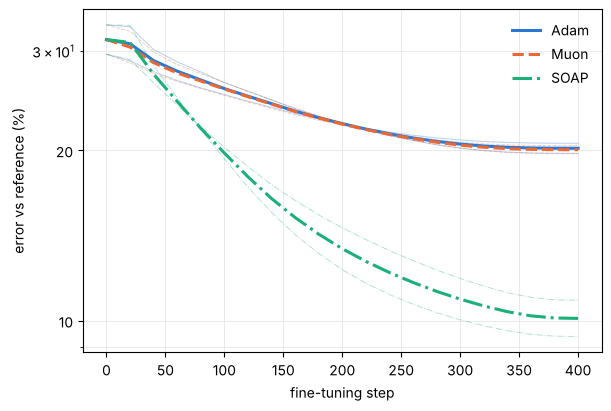

In [10]:
fig = an.plot_phase2(PDE, CN, x='it'); plt.show()

## Observations

- **Phase 1 never left the early regime at this scale.** All three end at ≈34–35% on the fine grids. Simply predicting no change, $w(t) = w_0$, scores 37.4% on this test set. The paper reaches ≈6% with a wider model and far more compute.
- **Muon is marginally ahead of Adam** (34.3% vs 34.7%).
- **SOAP fits the coarse 32² × 17 data grid much better (24.8%), but not the finer grids** (35.2% on the PDE grid). Its operator is strongly resolution-dependent; Adam's and Muon's are flat. One reason to evaluate operators away from their training resolution.
- **Phase 2 is where SOAP stands out:** from 31.5%, after 400 steps, Adam 20.2%, Muon 20.1%, **SOAP 10.2%**. That's half the error in about the same time. On this hard, chaotic single-instance problem, curvature-aware updates help most.
- **The Crank–Nicolson rerun gives the same answer:** Adam 20.2%, Muon 20.1%, SOAP 10.1%. The exact minimizer of that loss is only 0.7% from the reference, so every optimizer stops 15–30× above what the loss allows: this solve is limited by the optimizer, not the grid.
- **Caveats:** one seed, untuned learning rates and only 2 fine-tuning instances. Muon and SOAP also ran during a host slowdown (steps ≈1.7× slower), so **compare Kolmogorov by iterations, not wall time**. Muon-spec was not run on this problem.